In [1]:

!pip install -q pandas numpy matplotlib seaborn nltk wordcloud scikit-learn pyLDAvis


In [2]:

!git clone --depth 1 https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing.git

import os

repo_path = "/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing"

data_files = []

for root, dirs, files in os.walk(repo_path):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    for file in files:
        if file.lower().endswith((".csv", ".json", ".jsonl")):
            data_files.append(os.path.join(root, file))

print("Dataset files found:")
for file in data_files:
    print(file)


Cloning into 'Health-Related-Headlines-Datasets-for-Natural-Language-Processing'...
remote: Enumerating objects: 63, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 63 (delta 25), reused 62 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (63/63), 12.82 MiB | 27.18 MiB/s, done.
Resolving deltas: 100% (25/25), done.
Dataset files found:
/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Adverse_Drug_Reaction_Journals_Headlines.csv
/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Health_Related_Headlines_Dataset.csv
/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Antibiotic_Resistance_Journals_Headlines.csv
/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Substance_Abuse_and_Addiction_Perspective_Headlines.csv
/content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Peadiatric_Immunization_New

In [3]:

import pandas as pd
import os

if not data_files:
    raise FileNotFoundError(
        "No CSV or JSON dataset found. Check the repository files."
    )

dataset_file = max(data_files, key=os.path.getsize)
print("Selected file:", dataset_file)

if dataset_file.lower().endswith(".csv"):
    df = pd.read_csv(dataset_file)
elif dataset_file.lower().endswith(".jsonl"):
    df = pd.read_json(dataset_file, lines=True)
else:
    df = pd.read_json(dataset_file)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Selected file: /content/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Health_Related_Headlines_Dataset.csv
Dataset shape: (39405, 5)

Column names:
['Date', 'Source', 'Headlines', 'Teaser', 'Category']

First five rows:


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management


In [4]:

# Automatically detect a likely text column
possible_names = [
    "headline", "headlines", "title", "titles",
    "teaser", "text", "content", "description", "article"
]

column_lookup = {str(c).lower().strip(): c for c in df.columns}

text_column = next(
    (column_lookup[name] for name in possible_names
     if name in column_lookup),
    None
)

print("Detected text column:", text_column)

# If no column is detected, inspect df.columns and set it manually.
# Example: text_column = "Headline"

if text_column is None:
    print("Available columns:", df.columns.tolist())
    raise ValueError(
        "Set text_column manually to the column containing headlines."
    )

df = df.dropna(subset=[text_column]).copy()
df["raw_text"] = df[text_column].astype(str).str.strip()
df = df[df["raw_text"] != ""]

print("Number of usable text records:", len(df))
display(df[["raw_text"]].head())


Detected text column: Headlines
Number of usable text records: 39405


,raw_text
0,Special Report: Adult Vaccines -- New ACIP Rec...
1,Combined Internet and Telephone Intervention M...
2,Link Between Parental Alcoholism and Childhood...
3,Methadone Dose in the Treatment of Opiate Depe...
4,Magnet Treatment Had No Beneficial Effect on P...


In [5]:

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger_eng")


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [6]:

import re
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Lowercase
    text = text.lower()

    # Remove URLs and punctuation
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    # Tokenization
    tokens = word_tokenize(text)

    # Stop-word removal and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return cleaned_tokens

df["tokens"] = df["raw_text"].apply(clean_text)
df["cleaned_text"] = df["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

print("Original and cleaned samples:")
display(df[["raw_text", "cleaned_text"]].head(10))


Original and cleaned samples:


,raw_text,cleaned_text
0,Special Report: Adult Vaccines -- New ACIP Rec...,special report adult vaccine new acip recommen...
1,Combined Internet and Telephone Intervention M...,combined internet telephone intervention may f...
2,Link Between Parental Alcoholism and Childhood...,link parental alcoholism childhood mood disorder
3,Methadone Dose in the Treatment of Opiate Depe...,methadone dose treatment opiate dependence
4,Magnet Treatment Had No Beneficial Effect on P...,magnet treatment beneficial effect patient chr...
5,Ask the Experts - Investigational Agents for M...,ask expert investigational agent mesothelioma
6,Estrogen Replacement May Negate the Benefits o...,estrogen replacement may negate benefit growth...
7,MEDLINE Abstracts: Thalidomide Clinical Trials,medline abstract thalidomide clinical trial
8,IRB/FDA Requirements Relevant to HIV/AIDS Clin...,irb fda requirement relevant hiv aid clinical ...
9,HIV Clinical Trials in Correctional Settings: ...,hiv clinical trial correctional setting right ...


In [7]:

from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

all_words = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

word_counts = Counter(all_words)

print("Total words after preprocessing:", len(all_words))
print("Unique words:", len(word_counts))

print("\nTop 20 frequent words:")
for word, count in word_counts.most_common(20):
    print(f"{word}: {count}")


Total words after preprocessing: 228945
Unique words: 15792

Top 20 frequent words:
patient: 2860
risk: 2653
cancer: 2458
drug: 2385
pain: 2319
new: 1743
vaccine: 1595
may: 1566
use: 1557
fda: 1496
treatment: 1485
opioid: 1251
disease: 1206
therapy: 1147
care: 1004
linked: 868
chronic: 813
trial: 807
child: 777
hiv: 740


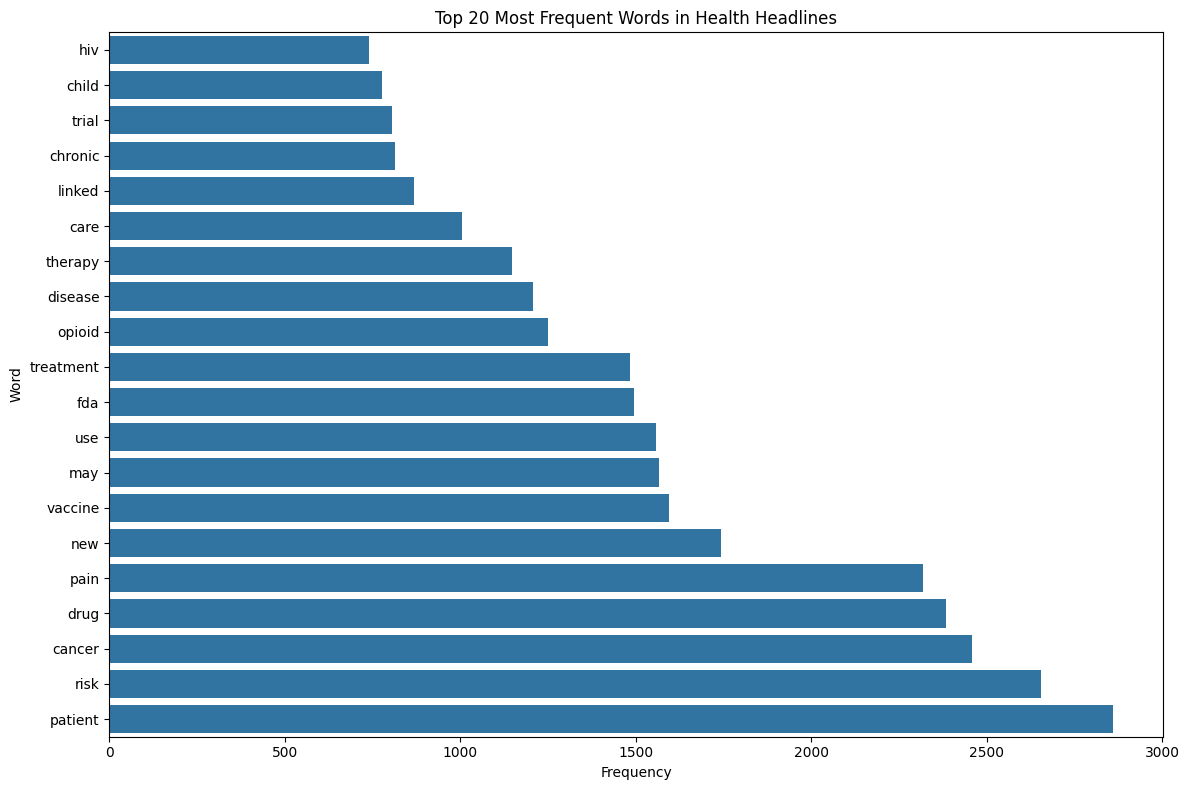

In [8]:

top_20 = word_counts.most_common(20)

freq_df = pd.DataFrame(
    top_20, columns=["Word", "Frequency"]
).sort_values("Frequency", ascending=True)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=freq_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words in Health Headlines")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


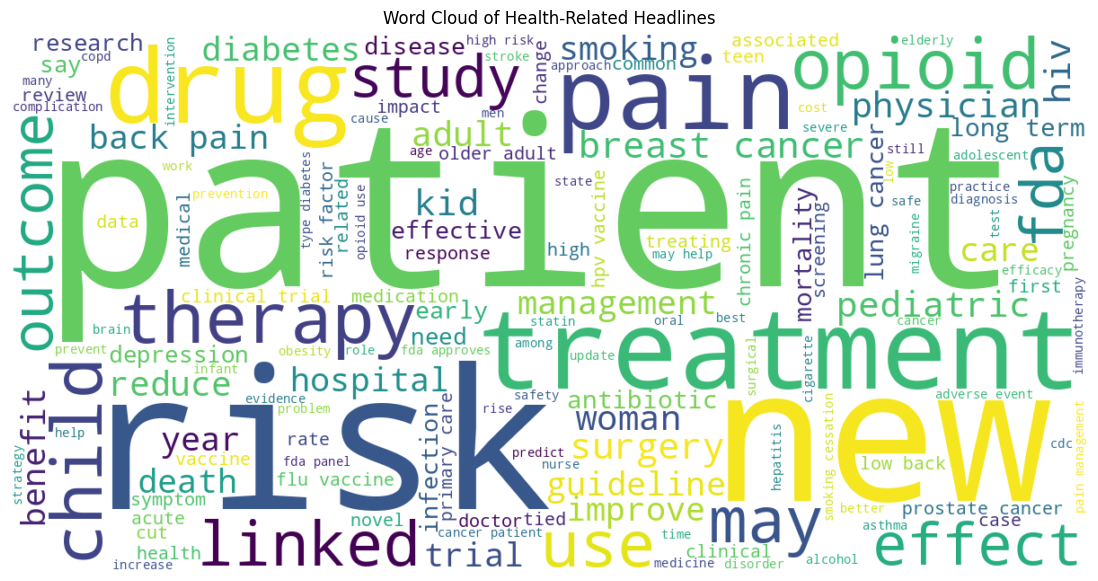

In [9]:

from wordcloud import WordCloud

text_corpus = " ".join(df["cleaned_text"].tolist())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    colormap="viridis"
).generate(text_corpus)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Health-Related Headlines")
plt.show()


In [10]:

wordcloud.to_file("/content/health_wordcloud.png")
print("Word cloud saved successfully.")


Word cloud saved successfully.


In [11]:

from sklearn.feature_extraction.text import CountVectorizer

documents = df["cleaned_text"].tolist()

vectorizer = CountVectorizer(
    max_df=1.0,
    min_df=1,
    max_features=5000
)

document_term_matrix = vectorizer.fit_transform(documents)

print("Document-term matrix shape:",
      document_term_matrix.shape)
print("Vocabulary size:",
      len(vectorizer.get_feature_names_out()))


Document-term matrix shape: (39405, 5000)
Vocabulary size: 5000


In [12]:

from sklearn.decomposition import LatentDirichletAllocation

n_topics = 5

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=10,
    learning_method="batch"
)

lda_model.fit(document_term_matrix)

print("LDA model trained successfully.")


LDA model trained successfully.


In [13]:

feature_names = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")


Topic 1: cancer, risk, vaccine, drug, year
Topic 2: pain, patient, chronic, management, back
Topic 3: new, drug, fda, trial, vaccine
Topic 4: patient, care, risk, disease, diabetes
Topic 5: child, use, may, smoking, health


In [14]:

import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    vectorizer,
    sort_topics=False
)

pyLDAvis.display(vis)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [15]:

topic_probabilities = lda_model.transform(document_term_matrix)

df["dominant_topic"] = (
    topic_probabilities.argmax(axis=1) + 1
)

df["topic_probability"] = topic_probabilities.max(axis=1)

print("Sample headlines with their dominant topics:")
display(
    df[["raw_text", "cleaned_text",
        "dominant_topic", "topic_probability"]].head(10)
)

print("\nNumber of documents in each topic:")
print(df["dominant_topic"].value_counts().sort_index())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sample headlines with their dominant topics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,raw_text,cleaned_text,dominant_topic,topic_probability
0,Special Report: Adult Vaccines -- New ACIP Rec...,special report adult vaccine new acip recommen...,3,0.572496
1,Combined Internet and Telephone Intervention M...,combined internet telephone intervention may f...,5,0.571073
2,Link Between Parental Alcoholism and Childhood...,link parental alcoholism childhood mood disorder,5,0.540677
3,Methadone Dose in the Treatment of Opiate Depe...,methadone dose treatment opiate dependence,5,0.863865
4,Magnet Treatment Had No Beneficial Effect on P...,magnet treatment beneficial effect patient chr...,2,0.549813
5,Ask the Experts - Investigational Agents for M...,ask expert investigational agent mesothelioma,2,0.458286
6,Estrogen Replacement May Negate the Benefits o...,estrogen replacement may negate benefit growth...,5,0.572632
7,MEDLINE Abstracts: Thalidomide Clinical Trials,medline abstract thalidomide clinical trial,2,0.445711
8,IRB/FDA Requirements Relevant to HIV/AIDS Clin...,irb fda requirement relevant hiv aid clinical ...,3,0.898784
9,HIV Clinical Trials in Correctional Settings: ...,hiv clinical trial correctional setting right ...,3,0.678978



Number of documents in each topic:
dominant_topic
1    8218
2    7551
3    8226
4    8053
5    7357
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **Conclusion**

**In this assignment, NLP techniques were applied to healthcare-related headlines to analyze and understand medical text data. The dataset was cleaned using lowercasing, punctuation removal, tokenization, stop-word removal, and lemmatization. Word frequency analysis and a word cloud were used to identify commonly occurring terms. The top 20 words were visualized using a bar chart. Finally, Latent Dirichlet Allocation (LDA) was applied to discover major topics in the dataset, and pyLDAvis was used to explore the resulting topics interactively. This assignment demonstrates how NLP and topic modeling can help identify patterns and trends in healthcare-related text.**